# COMP3602 · Week 4 Lab — Investigating Student Learning Data
**From messy records to reliable insights** · 90 minutes · Beginner–intermediate

**Scenario:** The university wants to examine student learning habits, exam performance, and attendance. You have two CSV files that contain deliberate data-quality problems. Investigate before changing anything.

**Files:** `student_learning.csv`, `student_attendance.csv` (place in the same folder as this notebook).

**Objectives:** Identify and justify cleaning decisions; detect outliers using IQR and Z-score; inspect noisy numerical data visually; merge two sources; use Week 3 frequency distributions and charts; use Week 2 simple random sampling.

**Important:** An unusual value is not automatically wrong. Write short explanations alongside your code. Use simple Pandas and Matplotlib commands.

**Data dictionary**

| Column | Meaning / expected range |
|---|---|
| Student_ID | Student identifier; one record per student expected |
| Age | Years; normally 18–25 |
| Program | CS, AI, IT, DS (equivalent full names may appear) |
| City | Muscat, Seeb, Sohar, Nizwa |
| Study_Hours | Average **daily** study hours; most students expected near 1–10 |
| Screen_Time | Average daily **recreational** screen hours; measurements can naturally vary |
| Exam_Score | Exam mark, 0–100 |
| StudentNo | Student identifier in the attendance file |
| Attendance | Attendance percentage, 0–100 |

**Guidance:** Complete the code cells and answer the written questions. The tasks deliberately mix topics rather than following lecture order.

## Setup — Load both CSV files

In [28]:
# === Write your answer here: ===
import pandas as pd
import matplotlib.pyplot as plt

students = pd.read_csv('student_learning.csv')
attendance = pd.read_csv('student_attendance.csv')


students.head(10)


,Student_ID,Age,Program,City,Study_Hours,Screen_Time,Exam_Score
0,S101,24.0,CS,Muscat,4.9,6.0,73.0
1,S102,18.0,AI,Nizwa,3.8,5.0,56.0
2,S103,19.0,IT,muscat,3.4,5.5,55.0
3,S104,21.0,DS,Seeb,2.0,7.4,50.0
4,S105,NaN,CS,Muscat,4.6,5.2,70.0
5,S106,24.0,cs,Nizwa,3.2,6.7,59.0
6,S107,21.0,IT,Sohar,2.3,5.4,59.0
7,S108,24.0,DS,Sohar,7.5,3.5,87.0
8,S109,18.0,CS,Seeb,3.4,5.6,52.0
9,S110,24.0,AI,Muscat,3.1,5.0,76.0


## Investigation 1 — Count students in each academic program
1. Check the number of rows, missing values, and duplicate rows. 2. Display the raw frequency of each `Program` category and draw a bar chart. 3. Explain why the first bar chart may be misleading and what must be standardized.

**Hint:** `shape`, `isnull().sum()`, `duplicated().sum()`, `value_counts()`, `plot(kind="bar")`.

**Explain:** Do differently written labels necessarily represent different programs?

Shape of the dataset: (82, 7)
Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 82 entries, 0 to 81
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Student_ID   82 non-null     str    
 1   Age          79 non-null     float64
 2   Program      82 non-null     str    
 3   City         80 non-null     str    
 4   Study_Hours  82 non-null     float64
 5   Screen_Time  82 non-null     float64
 6   Exam_Score   80 non-null     float64
dtypes: float64(4), str(3)
memory usage: 4.6 KB
Missing values in each column:
Student_ID     0
Age            3
Program        0
City           2
Study_Hours    0
Screen_Time    0
Exam_Score     2
dtype: int64
Number of duplicate rows:
2
Number of students in each program:
Program
CS                         21
DS                         21
IT                         20
AI                         12
cs                          1
Computer Science            1
ai               

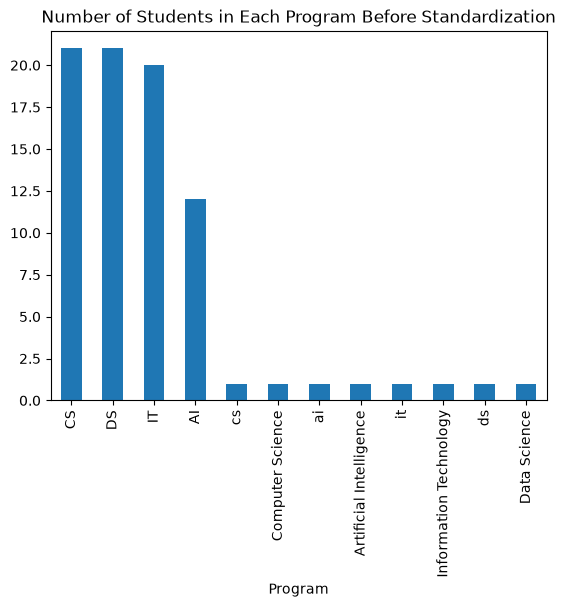

Number of students in each program after standardization:
Program
CS    23
DS    23
IT    22
AI    14
Name: count, dtype: int64


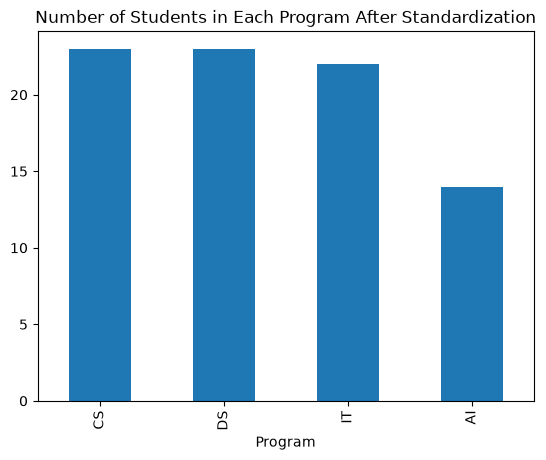

In [ ]:
# === Write your answer here: ===
print("Shape of the dataset:", students.shape)
print("Dataset information:")
students.info()
print("Missing values in each column:")
print(students.isnull().sum())
print("Number of duplicate rows:")
print(students.duplicated().sum())
print("Number of students in each program:")
print(students["Program"].value_counts(dropna=False))
students["Program"].value_counts(dropna=False).plot(kind='bar', title='Number of Students in Each Program Before Standardization')
plt.show()


students["Program"] = students["Program"].replace({
    "Data Science": "DS",
    "ds": "DS",
    "Computer Science": "CS",
    "cs": "CS",
    "Artificial Intelligence": "AI",
    "ai": "AI",
    "Information Technology": "IT",
    "it": "IT"
})

print("Number of students in each program after standardization:")
print(students["Program"].value_counts(dropna=False))
students["Program"].value_counts(dropna=False).plot(kind='bar', title='Number of Students in Each Program After Standardization')
plt.show()




## Investigation 2 — Identify unusual daily study-hour values
1. Draw a box plot of `Study_Hours`. 2. Calculate Q1, Q3, IQR, and the lower/upper fences. 3. Display records flagged by IQR. 4. Calculate Z-scores using the **population standard deviation** (`ddof=0`), and display records with `|z| > 3`. 5. Compare the two methods. **Do not delete flagged rows.**

**Hint:** Use `quantile(0.25)`, `quantile(0.75)`, `mean()`, `std(ddof=0)`, and Boolean filtering. Work on the original data before making corrections.

**Explain:** Are IQR and Z-score guaranteed to flag identical records? Why not?

C:\Users\ibnHi\AppData\Local\Temp\ipykernel_3980\2558135218.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(students["Study_Hours"], vert=False)


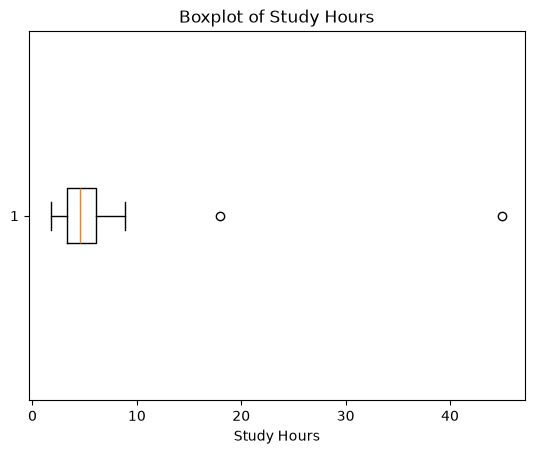


Q1: 3.3
Q3: 6.1
IQR: 2.8

Lower Bound: -0.8999999999999995
Upper Bound: 10.299999999999999

Outliers in Study Hours:
   Student_ID   Age Program   City  Study_Hours  Screen_Time  Exam_Score
39       S140  19.0      DS  Sohar         45.0          7.0        54.0
73       S173  25.0      CS  Sohar         18.0          6.3        42.0

Z-score of Study Hours:
0    -0.091443
1    -0.316190
2    -0.397916
3    -0.683957
4    -0.152738
        ...   
77    0.153735
78   -0.132306
79    0.398913
80   -0.295758
81   -0.214032
Name: Study_Hours, Length: 82, dtype: float64

Outliers based on Z-score:
   Student_ID   Age Program   City  Study_Hours  Screen_Time  Exam_Score
39       S140  19.0      DS  Sohar         45.0          7.0        54.0


In [41]:
# === Write your answer here: ===
plt.boxplot(students["Study_Hours"], vert=False)
plt.title("Boxplot of Study Hours")
plt.xlabel("Study Hours")
plt.show()
print()
q1 = students["Study_Hours"].quantile(0.25)
q3 = students["Study_Hours"].quantile(0.75)
iqr = q3 - q1
print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)

print()
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print()
print("Outliers in Study Hours:")
outliers = students[(students["Study_Hours"] < lower_bound) | (students["Study_Hours"] > upper_bound)]
print(outliers)
print()

z_score = (students["Study_Hours"] - students["Study_Hours"].mean()) / students["Study_Hours"].std(ddof=0)
print("Z-score of Study Hours:")
print(z_score)

outliers_z = students[abs(z_score) > 3]
print()
print("Outliers based on Z-score:")
print(outliers_z)

#There is difference between the two methods of outlier detection.
#The IQR method identified 2 outliers, while the Z-score method identified 1 outlier.
#This difference is due to the fact that the IQR method is based on the spread of the data, while the Z-score method is based on the standard deviation. 
#The IQR method is more robust to outliers, while the Z-score method is more sensitive to outliers.


### Verification note — provided by the university data team
The record for **S140** contains a confirmed typing error: `Study_Hours = 45.0` should be **4.5**. The unusually high study-hours value for **S173** has **not** been verified and must **not** be automatically replaced or deleted. Keep it in the data and document the concern.

**Decision:** Correct only the verified error. Keep the unverified value and consider its effect when interpreting charts.

## Investigation 3 — Produce a consistent student dataset
1. Remove exact duplicate rows. 2. Correct the **verified** study-hours error using `Student_ID`. 3. Replace missing ages with the median; replace missing cities with `Unknown`; for this exercise, exclude records with missing `Exam_Score` from subsequent exam-score analysis. 4. Standardize program and city labels. 5. Verify missing counts, duplicate counts, and program frequencies.

**Hint:** Use `drop_duplicates()`, `loc[]`, `fillna()`, `dropna(subset=...)`, `replace()`, and `str.title()`. Do not change S173.

**Explain:** Which cleaning steps change the number of records, and which only change values?

In [ ]:
# === Write your answer here: ===


## Investigation 4 — Combine attendance with the cleaned records
1. Inspect `student_attendance.csv`. 2. Rename `StudentNo` to `Student_ID`. 3. Merge it with the cleaned student data on that identifier, using an **inner** join. 4. Check the row count and missing values after merging.

**Hint:** Use `rename(columns={...})`, `pd.merge(..., on="Student_ID", how="inner")`.

**Explain:** Why is checking the row count after a merge important?

In [ ]:
# === Write your answer here: ===


## Investigation 5 — Summarize the distribution of exam scores
1. Create a grouped frequency table with intervals **[0, 40), [40, 50), …, [90, 101)**. 2. Add a cumulative-frequency column. 3. Draw a histogram using the same bin boundaries. 4. Interpret which score range has the highest frequency. **Optional:** draw an ogive using cumulative frequencies.

**Hint:** Use `pd.cut()`, `value_counts(sort=False)`, `cumsum()`, and `plot(kind="hist", bins=...)`. The final upper boundary is 101 to include a score of 100.

**Explain:** What does cumulative frequency tell us that ordinary frequency does not?

In [ ]:
# === Write your answer here: ===


## Investigation 6 — Compare a random sample with the cleaned dataset
1. Draw a **simple random sample of 20 students** from the merged data using `random_state=42`. 2. Calculate mean exam score for the sample and the full merged dataset. 3. Compare them. 4. Explain whether one sample is guaranteed to have exactly the same mean as the full dataset.

**Hint:** Use `sample(n=20, random_state=42)` and `mean()`.

**Explain:** Does simple random sampling guarantee a representative sample in every draw?

In [ ]:
# === Write your answer here: ===


## Investigation 7 — Make two charts and interpret them responsibly
1. Create a **bar chart** of the cleaned program counts. 2. Draw a **scatter plot** of study hours against exam score. 3. Inspect the distribution of `Screen_Time` using a histogram and describe its natural variation; **do not smooth or replace values**. 4. Explain how the unverified high study-hours observation could influence the scatter plot. 5. Save the prepared dataset as `student_learning_prepared.csv`.

**Hint:** Use `value_counts().plot(kind="bar")`, `plot(kind="scatter")`, `plot(kind="hist")`, and `to_csv(index=False)`.

**Explain:** Does an unusual value automatically indicate measurement noise? What information would you need before changing it?

In [ ]:
# === Write your answer here: ===


## Final reflection (write 3–5 sentences)

1. Which two preprocessing decisions mattered most for reliable analysis?
2. How did Week 3 visualization help you detect or understand a problem?
3. What did the Week 2 random sample show you about variation between a sample and the full dataset?

**Reminder:** Good data analysis requires both correct Python operations and defensible decisions.